In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/SeoulBikeData.csv


In [2]:
# importing liberaries
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 

In [3]:
# data loading 
df =  pd.read_csv('/kaggle/input/SeoulBikeData.csv',encoding='latin1')
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [4]:
df.shape

(8760, 14)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   object 
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   object 
 12  Holiday                    8760 non-null   object 
 13  Functioning Day            8760 non-null   objec

In [6]:
df.describe()

,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm)
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.isnull().sum()

Date                         0
Rented Bike Count            0
Hour                         0
Temperature(°C)              0
Humidity(%)                  0
Wind speed (m/s)             0
Visibility (10m)             0
Dew point temperature(°C)    0
Solar Radiation (MJ/m2)      0
Rainfall(mm)                 0
Snowfall (cm)                0
Seasons                      0
Holiday                      0
Functioning Day              0
dtype: int64

In [9]:
df['Date'].unique()

array(['01/12/2017', '02/12/2017', '03/12/2017', '04/12/2017',
       '05/12/2017', '06/12/2017', '07/12/2017', '08/12/2017',
       '09/12/2017', '10/12/2017', '11/12/2017', '12/12/2017',
       '13/12/2017', '14/12/2017', '15/12/2017', '16/12/2017',
       '17/12/2017', '18/12/2017', '19/12/2017', '20/12/2017',
       '21/12/2017', '22/12/2017', '23/12/2017', '24/12/2017',
       '25/12/2017', '26/12/2017', '27/12/2017', '28/12/2017',
       '29/12/2017', '30/12/2017', '31/12/2017', '01/01/2018',
       '02/01/2018', '03/01/2018', '04/01/2018', '05/01/2018',
       '06/01/2018', '07/01/2018', '08/01/2018', '09/01/2018',
       '10/01/2018', '11/01/2018', '12/01/2018', '13/01/2018',
       '14/01/2018', '15/01/2018', '16/01/2018', '17/01/2018',
       '18/01/2018', '19/01/2018', '20/01/2018', '21/01/2018',
       '22/01/2018', '23/01/2018', '24/01/2018', '25/01/2018',
       '26/01/2018', '27/01/2018', '28/01/2018', '29/01/2018',
       '30/01/2018', '31/01/2018', '01/02/2018', '02/02

In [10]:
df['Temperature(°C)'].unique()

array([ -5.2,  -5.5,  -6. ,  -6.2,  -6.4,  -6.6,  -7.4,  -7.6,  -6.5,
        -3.5,  -0.5,   1.7,   2.4,   3. ,   2.1,   1.2,   0.8,   0.6,
         0. ,  -0.3,  -0.8,  -0.9,  -1.3,  -1.8,  -2.2,  -2.9,  -3.8,
        -4. ,  -4.3,  -4.4,  -4.2,  -0.4,   1.9,   4.3,   6. ,   7.3,
         7.6,   6.4,   5.5,   5. ,   4.6,   4.1,   3.5,   4. ,   3.9,
         3.3,   3.4,   3.1,   3.2,   4.4,   5.1,   5.8,   6.8,   8. ,
         6.7,   5.7,   5.2,   4.7,   4.2,   3.6,   2.8,   2. ,   0.2,
        -1.5,  -1.1,   0.1,  -0.1,  -0.2,  -2.1,  -3.6,  -4.6,  -5.3,
        -5.8,  -6.1,  -6.8,  -6.9,  -7.2,  -7.5,  -8.1,  -3.9,  -2.3,
        -1.6,  -0.7,  -2.6,  -3.2,  -3.7,  -2.8,  -2.5,  -3. ,  -3.4,
        -3.3,   1.6,   5.3,   1.1,   1.3,   1.4,   1.5,   1. ,   0.3,
         2.3,   3.7,   0.7,  -1.4,  -2.7,  -4.8,  -7. ,  -6.7,  -2. ,
        -1.7,  -2.4,  -3.1,  -4.1,  -4.7,  -5.1,  -5.4,   2.5,   0.4,
         0.5,   0.9,   5.4,  -1. ,  -5.6,  -5.9,  -7.1,  -7.9,  -8.6,
        -9.3,  -9.7,

In [11]:
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [12]:
# convert into Date datetime 
df['Date'] = pd.to_datetime(df['Date'], format =  "%d/%m/%Y")

## Checking Column by Column 

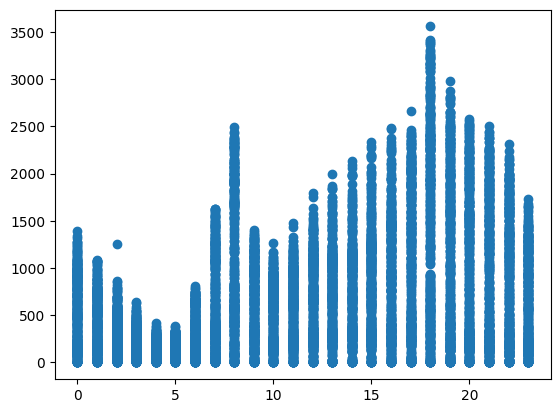

In [13]:
plt.scatter(x='Hour', y ='Rented Bike Count', data = df)
plt.show()

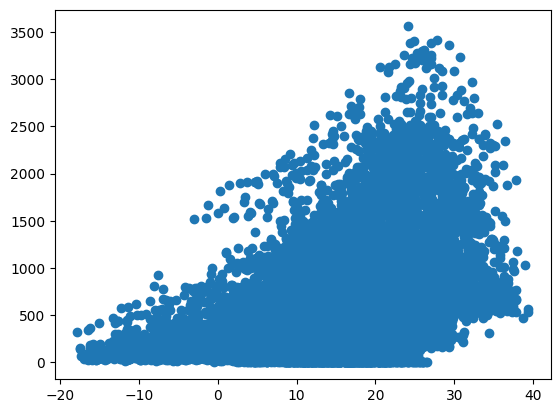

In [14]:
plt.scatter(x='Temperature(°C)', y ='Rented Bike Count', data = df)
plt.show()

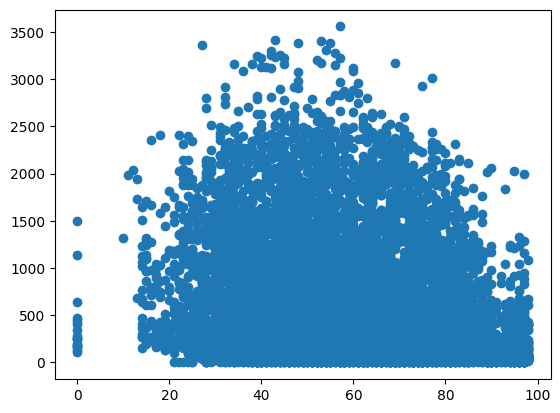

In [15]:
plt.scatter(x='Humidity(%)', y ='Rented Bike Count', data = df)
plt.show()

In [16]:
df.query("`Humidity(%)` == 0")
# trip them as data errors 
#4063,4106,4107,4108,4109,4110,4111,4131,4132,4133,4134,4253,4255,4276,4278,4279

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
4063,2018-05-19,436,7,11.4,0,1.4,2000,4.5,0.46,0.0,0.0,Spring,No Holiday,Yes
4106,2018-05-21,262,2,13.9,0,0.9,2000,-2.1,0.00,0.0,0.0,Spring,No Holiday,Yes
4107,2018-05-21,165,3,13.0,0,0.8,2000,-2.5,0.00,0.0,0.0,Spring,No Holiday,Yes
4108,2018-05-21,113,4,12.4,0,0.8,2000,-3.4,0.00,0.0,0.0,Spring,No Holiday,Yes
4109,2018-05-21,200,5,11.9,0,1.3,2000,-2.7,0.00,0.0,0.0,Spring,No Holiday,Yes
4110,2018-05-21,467,6,11.4,0,0.9,2000,-2.0,0.03,0.0,0.0,Spring,No Holiday,Yes
4111,2018-05-21,1135,7,12.3,0,0.9,1989,-2.7,0.48,0.0,0.0,Spring,No Holiday,Yes
4131,2018-05-22,406,3,15.5,0,0.7,1420,10.4,0.00,0.0,0.0,Spring,Holiday,Yes
4132,2018-05-22,248,4,15.6,0,0.5,1502,10.5,0.00,0.0,0.0,Spring,Holiday,Yes
4133,2018-05-22,182,5,15.7,0,0.6,1610,10.6,0.00,0.0,0.0,Spring,Holiday,Yes


In [17]:
# replacing the 0 with the nan values 
df.loc[df['Humidity(%)'] == 0, 'Humidity(%)'] = np.nan
# replacing the nan values with the median values
df['Humidity(%)'].fillna(df['Humidity(%)'].median(), inplace=True)


/tmp/ipykernel_23/1710515398.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Humidity(%)'].fillna(df['Humidity(%)'].median(), inplace=True)


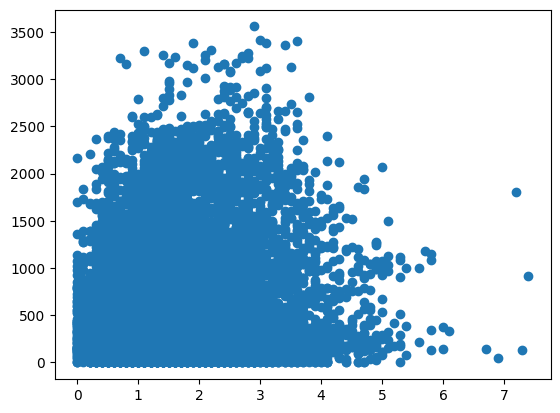

In [18]:
plt.scatter(x='Wind speed (m/s)', y ='Rented Bike Count', data = df)
plt.show()

In [19]:
df.query("`Wind speed (m/s)` > 6.5 ")
# 933,3134,3138,3141,6316

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
933,2018-01-08,146,21,0.7,77.0,6.7,692,-2.8,0.0,0.9,1.0,Winter,No Holiday,Yes
3134,2018-04-10,913,14,21.2,35.0,7.4,1992,5.1,1.8,0.0,0.0,Spring,No Holiday,Yes
3138,2018-04-10,1805,18,19.7,52.0,7.2,2000,9.5,0.2,0.0,0.0,Spring,No Holiday,Yes
3141,2018-04-10,133,21,17.5,70.0,7.3,1634,11.9,0.0,0.5,0.0,Spring,No Holiday,Yes
6316,2018-08-21,49,4,25.3,70.0,6.9,925,19.4,0.0,0.4,0.0,Summer,No Holiday,Yes


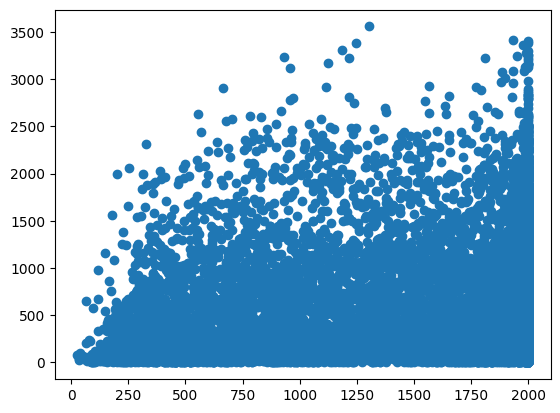

In [20]:
plt.scatter(x='Visibility (10m)', y ='Rented Bike Count', data = df)
plt.show()

In [21]:
df.query("`Visibility (10m)` < 1500 & `Rented Bike Count` > 3000 ")
# 4818 4842

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
4530,2018-06-07,3221,18,25.6,57.0,2.7,1217,16.4,0.96,0.0,0.0,Summer,No Holiday,Yes
4554,2018-06-08,3309,18,26.2,54.0,2.2,1183,16.1,0.88,0.0,0.0,Summer,No Holiday,Yes
4818,2018-06-19,3556,18,24.1,57.0,2.9,1301,15.0,0.56,0.0,0.0,Summer,No Holiday,Yes
4842,2018-06-20,3384,18,27.0,55.0,3.1,1246,17.1,1.26,0.0,0.0,Summer,No Holiday,Yes
4962,2018-06-25,3238,18,30.7,43.0,1.6,931,16.6,0.74,0.0,0.0,Summer,No Holiday,Yes
5010,2018-06-27,3172,18,25.0,69.0,1.5,1125,18.9,0.52,0.0,0.0,Summer,No Holiday,Yes
5058,2018-06-29,3113,18,28.1,60.0,1.9,959,19.5,1.05,0.0,0.0,Summer,No Holiday,Yes


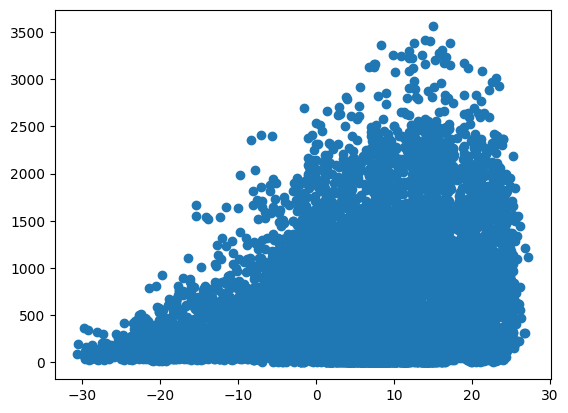

In [22]:
plt.scatter(x='Dew point temperature(°C)', y ='Rented Bike Count', data = df)
plt.show()

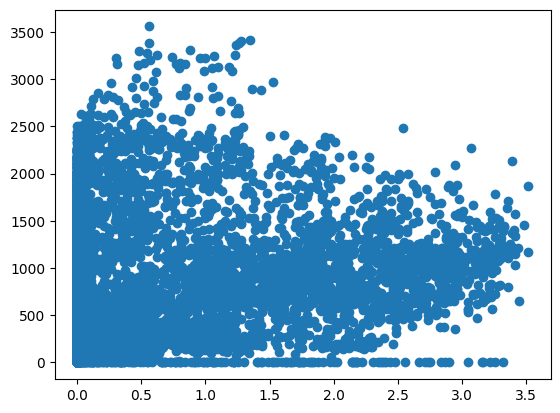

In [23]:
plt.scatter(x='Solar Radiation (MJ/m2)', y ='Rented Bike Count', data = df)
plt.show()

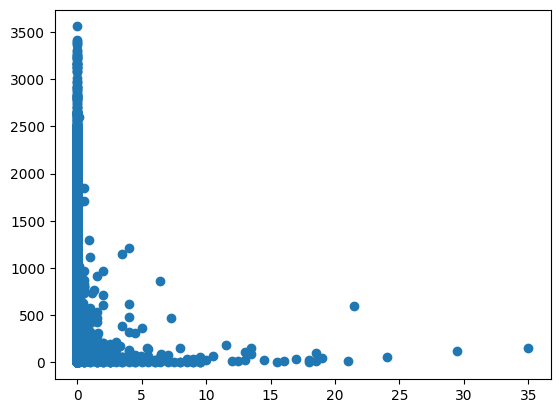

In [24]:
plt.scatter(x='Rainfall(mm)', y ='Rented Bike Count', data = df)
plt.show()
# do not remove the outliers 

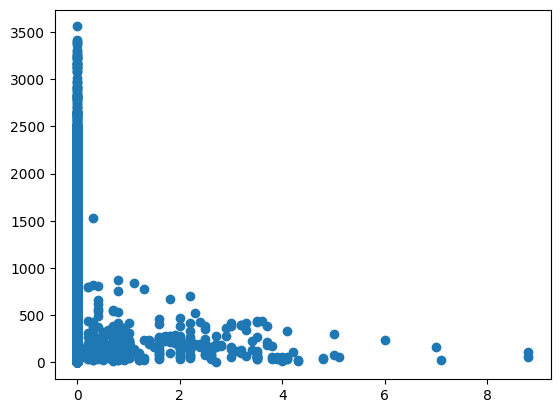

In [25]:
plt.scatter(x='Snowfall (cm)', y ='Rented Bike Count', data = df)
plt.show()
# dont remove the outliers it can be possible 

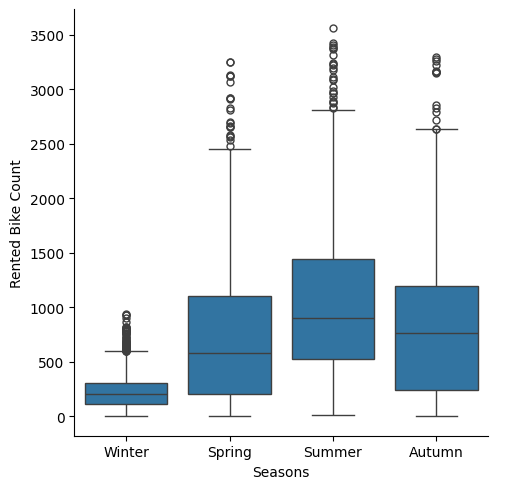

In [26]:
sns.catplot(x='Seasons' , y  = 'Rented Bike Count', data = df,kind = 'box')


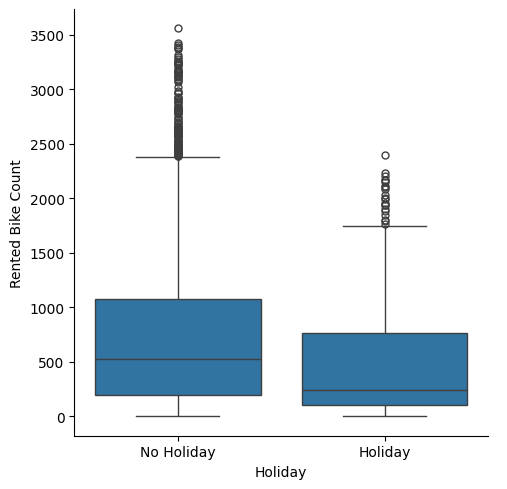

In [27]:
sns.catplot(x='Holiday' , y  = 'Rented Bike Count', data = df,kind = 'box')

In [28]:
df[df['Functioning Day'] == 'No']
# remove this columns 

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
3144,2018-04-11,0,0,14.4,82.0,4.6,1041,11.3,0.0,0.0,0.0,Spring,No Holiday,No
3145,2018-04-11,0,1,13.6,81.0,3.6,886,10.3,0.0,0.0,0.0,Spring,No Holiday,No
3146,2018-04-11,0,2,12.7,80.0,3.9,885,9.3,0.0,0.0,0.0,Spring,No Holiday,No
3147,2018-04-11,0,3,11.6,81.0,3.1,687,8.4,0.0,0.0,0.0,Spring,No Holiday,No
3148,2018-04-11,0,4,10.2,83.0,3.5,554,7.4,0.0,0.0,0.0,Spring,No Holiday,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8251,2018-11-09,0,19,11.9,71.0,2.7,589,6.7,0.0,0.0,0.0,Autumn,No Holiday,No
8252,2018-11-09,0,20,11.9,72.0,2.5,526,7.0,0.0,0.0,0.0,Autumn,No Holiday,No
8253,2018-11-09,0,21,11.4,74.0,1.9,498,6.9,0.0,0.0,0.0,Autumn,No Holiday,No
8254,2018-11-09,0,22,11.2,75.0,1.7,478,6.9,0.0,0.0,0.0,Autumn,No Holiday,No


In [29]:
# removing the columns with functional day =  no 
df = df[df['Functioning Day'] == 'Yes']

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8465 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       8465 non-null   datetime64[ns]
 1   Rented Bike Count          8465 non-null   int64         
 2   Hour                       8465 non-null   int64         
 3   Temperature(°C)            8465 non-null   float64       
 4   Humidity(%)                8465 non-null   float64       
 5   Wind speed (m/s)           8465 non-null   float64       
 6   Visibility (10m)           8465 non-null   int64         
 7   Dew point temperature(°C)  8465 non-null   float64       
 8   Solar Radiation (MJ/m2)    8465 non-null   float64       
 9   Rainfall(mm)               8465 non-null   float64       
 10  Snowfall (cm)              8465 non-null   float64       
 11  Seasons                    8465 non-null   object        
 12  Holiday    

In [31]:
# feature engineering 

In [32]:
# spliting date colunm in year month and day 
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Day'] = df['Date'].dt.day

/tmp/ipykernel_23/96610911.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Year'] = df['Date'].dt.year
/tmp/ipykernel_23/96610911.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Month'] = df['Date'].dt.month
/tmp/ipykernel_23/96610911.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.htm

In [33]:
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day,Year,Month,Day
0,2017-12-01,254,0,-5.2,37.0,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017,12,1
1,2017-12-01,204,1,-5.5,38.0,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017,12,1
2,2017-12-01,173,2,-6.0,39.0,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes,2017,12,1
3,2017-12-01,107,3,-6.2,40.0,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017,12,1
4,2017-12-01,78,4,-6.0,36.0,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017,12,1


In [34]:
# converting hour to morning afternoon evening and night 
bins = [0, 4, 12, 17, 21, 24] 
labels = ['Late Night','Morning', 'Afternoon', 'Evening', 'Night'] 

df['time_of_day'] = pd.cut(df['Hour'], bins=bins, labels=labels, right=False, include_lowest=True)

/tmp/ipykernel_23/2037317684.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['time_of_day'] = pd.cut(df['Hour'], bins=bins, labels=labels, right=False, include_lowest=True)


In [35]:
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day,Year,Month,Day,time_of_day
0,2017-12-01,254,0,-5.2,37.0,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017,12,1,Late Night
1,2017-12-01,204,1,-5.5,38.0,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017,12,1,Late Night
2,2017-12-01,173,2,-6.0,39.0,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes,2017,12,1,Late Night
3,2017-12-01,107,3,-6.2,40.0,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017,12,1,Late Night
4,2017-12-01,78,4,-6.0,36.0,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017,12,1,Morning


In [36]:
df[df['Rented Bike Count'] == 0]

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day,Year,Month,Day,time_of_day


<Axes: xlabel='Rented Bike Count', ylabel='Count'>

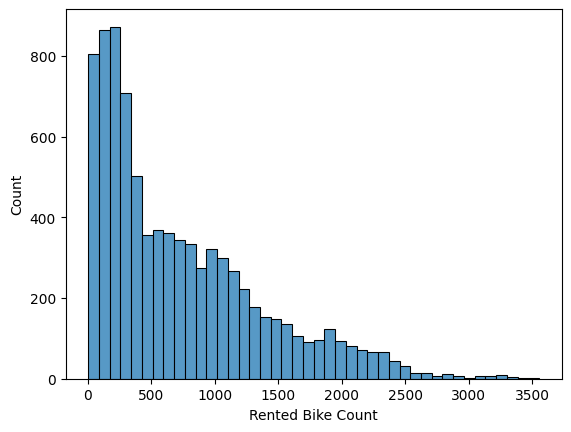

In [37]:
# eda 
sns.histplot(x='Rented Bike Count',data = df)

/tmp/ipykernel_23/2750242485.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Rented Bike Count'] = np.log1p(df['Rented Bike Count'])


<Axes: xlabel='Rented Bike Count', ylabel='Count'>

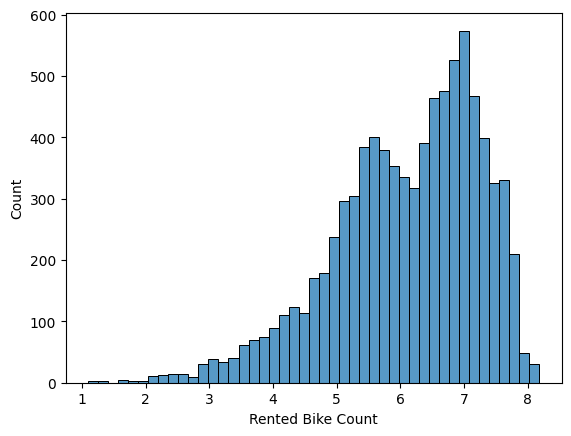

In [38]:
# it is left skeweed so use log transformation
df['Rented Bike Count'] = np.log1p(df['Rented Bike Count'])
sns.histplot(x='Rented Bike Count',data = df)

In [39]:
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day,Year,Month,Day,time_of_day
0,2017-12-01,5.541264,0,-5.2,37.0,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017,12,1,Late Night
1,2017-12-01,5.323010,1,-5.5,38.0,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017,12,1,Late Night
2,2017-12-01,5.159055,2,-6.0,39.0,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes,2017,12,1,Late Night
3,2017-12-01,4.682131,3,-6.2,40.0,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017,12,1,Late Night
4,2017-12-01,4.369448,4,-6.0,36.0,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes,2017,12,1,Morning


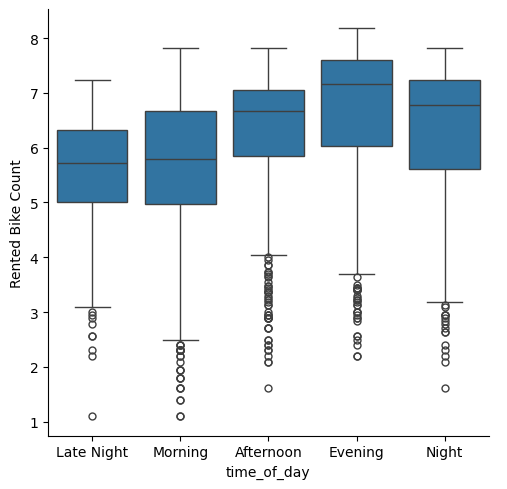

In [40]:
sns.catplot(x='time_of_day', y= 'Rented Bike Count', data = df, kind = 'box')

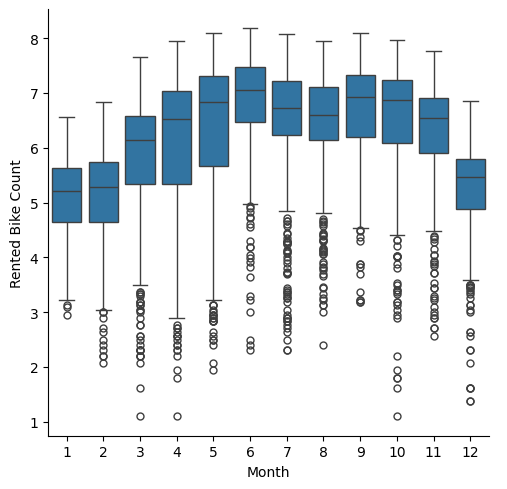

In [41]:
# month vs demand 
sns.catplot(x='Month', y= 'Rented Bike Count', data = df, kind = 'box')

<Axes: >

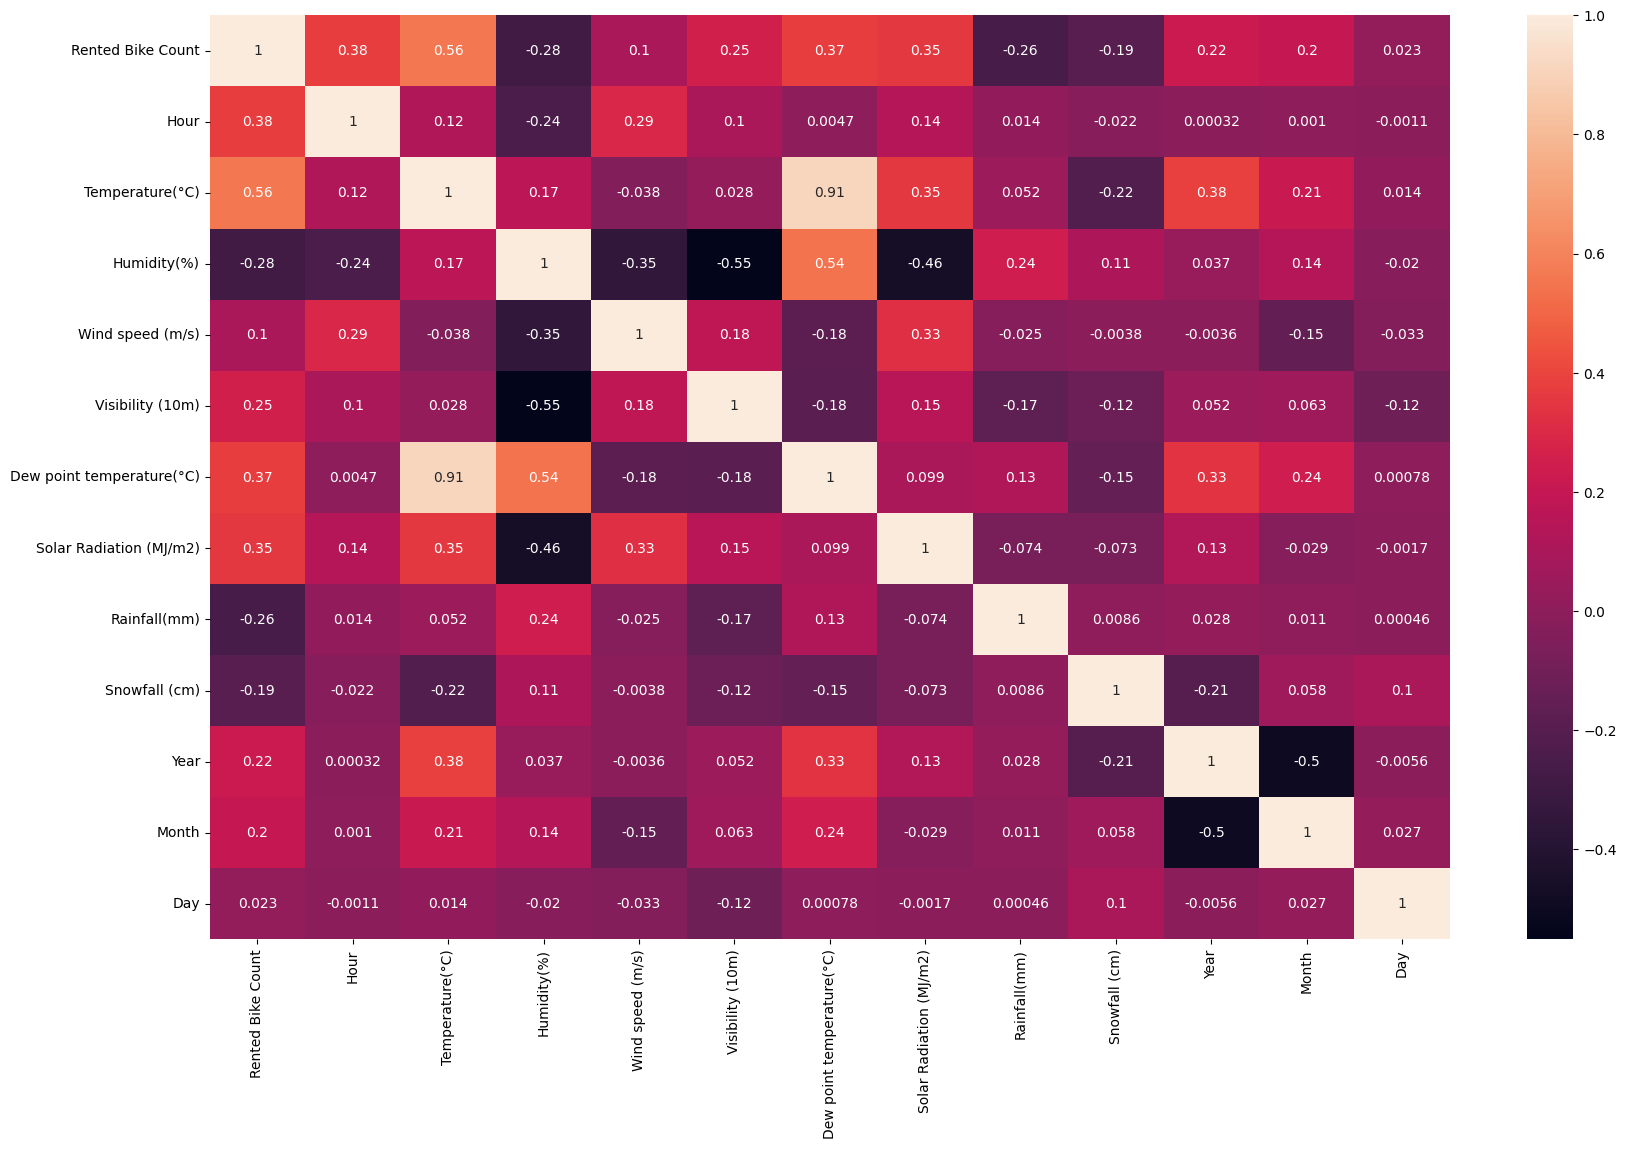

In [42]:
# correlation plot 
df_corr = df.corr(numeric_only = True)
plt.figure(figsize=(20,12))
sns.heatmap(df_corr,annot= True)

In [43]:
# droping Dew point temperature or Temperature because they are highly correalted 
df = df.drop(columns=['Dew point temperature(°C)']) # because it is less dependent on the target value 

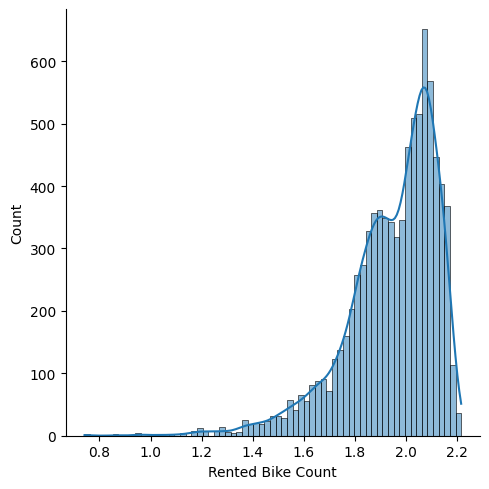

In [44]:
sns.displot(x=np.log1p(df['Rented Bike Count']),data=df,kde=True)

In [45]:
# splitiong into dependent and independent variables
X = df.drop(columns = ['Rented Bike Count'])
y = df['Rented Bike Count']

In [46]:
X.shape

(8465, 16)

In [47]:
df['time_of_day'] = df['time_of_day'].astype('object')

In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8465 entries, 0 to 8759
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Date                     8465 non-null   datetime64[ns]
 1   Rented Bike Count        8465 non-null   float64       
 2   Hour                     8465 non-null   int64         
 3   Temperature(°C)          8465 non-null   float64       
 4   Humidity(%)              8465 non-null   float64       
 5   Wind speed (m/s)         8465 non-null   float64       
 6   Visibility (10m)         8465 non-null   int64         
 7   Solar Radiation (MJ/m2)  8465 non-null   float64       
 8   Rainfall(mm)             8465 non-null   float64       
 9   Snowfall (cm)            8465 non-null   float64       
 10  Seasons                  8465 non-null   object        
 11  Holiday                  8465 non-null   object        
 12  Functioning Day          8465 non-null 

In [49]:
# drop the Date column
df = df.drop(columns = ['Date'])

In [50]:
# spliting columns into numerical and categorical columns 
cat_cols = [col for col in df if df[col].dtype == 'object']
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
num_cols = num_cols.drop('Rented Bike Count')

In [51]:
print(cat_cols)

['Seasons', 'Holiday', 'Functioning Day', 'time_of_day']


In [52]:
print(num_cols)

Index(['Hour', 'Temperature(°C)', 'Humidity(%)', 'Wind speed (m/s)',
       'Visibility (10m)', 'Solar Radiation (MJ/m2)', 'Rainfall(mm)',
       'Snowfall (cm)'],
      dtype='object')


In [53]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

In [54]:
# creating pipline 
preprocessor = ColumnTransformer(
    transformers=[
        ('ohe_p', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), cat_cols),
        
        ('num_p', Pipeline(steps=[
            ('imputer', SimpleImputer(strategy='mean')),
            ('scaler', StandardScaler())
        ]), num_cols)
    ]
)

In [55]:
# spliting the data into train test split
# train_test_split
from sklearn.model_selection import train_test_split
X_train, X_test , y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=25)

In [56]:
# fitting the pipline 
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [57]:
from sklearn.linear_model import LinearRegression
Lr = LinearRegression()

In [58]:
Lr.fit(X_train_processed,y_train)

LinearRegression()

In [59]:
y_pred = Lr.predict(X_test_processed)

In [60]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test,y_pred)
print(mse)
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)
print(r2)

0.4705871491924782
0.6327604969206895


In [61]:
# ridge regression 
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=1.0)
ridge.fit(X_train_processed, y_train)

Ridge()

In [62]:
y_pred_ridge = ridge.predict(X_test_processed)
mse = mean_squared_error(y_test,y_pred_ridge)
print(mse)
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred_ridge)
print(r2)

0.4705763442437383
0.6327689289486631


In [63]:
# selecting the best parameters 
from sklearn.model_selection import GridSearchCV
param_grid = {"alpha": [0.001, 0.01, 0.1, 1, 10, 100, 500]}
grid = GridSearchCV(Ridge(), param_grid, cv=5,
                    scoring="neg_mean_squared_error")
grid.fit(X_train_processed, y_train)
best_ridge = grid.best_estimator_
pred_best = best_ridge.predict(X_test_processed)
print(best_ridge)

Ridge(alpha=1)


In [64]:
# using cross validation in ridge 
from sklearn.linear_model import RidgeCV

ridge_cv = RidgeCV(alphas=[0.01, 0.1, 1, 10, 100])
ridge_cv.fit(X_train_processed, y_train)

ridge_cv.alpha_

np.float64(1.0)

In [65]:
# using lasso regression
from sklearn.linear_model import Lasso

lasso = Lasso(alpha=0.01)
lasso.fit(X_train_processed, y_train)

Lasso(alpha=0.01)

In [66]:
y_pred_lasso = lasso.predict(X_test_processed)
mse = mean_squared_error(y_test,y_pred_lasso)
print(mse)
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred_lasso)
print(r2)

0.47611213911206
0.6284488735453653


In [67]:
from sklearn.linear_model import ElasticNet

enet = ElasticNet(alpha=0.01, l1_ratio=0.5)
enet.fit(X_train_processed, y_train)

y_pred = enet.predict(X_test_processed)

print("R2:", r2_score(y_test, y_pred))

R2: 0.6304337220826748


In [68]:
# Decision Tree Regressor
from sklearn.tree import DecisionTreeRegressor

regressor = DecisionTreeRegressor(max_depth=3, random_state=42)
regressor.fit(X_train_processed, y_train)

# Predict
y_pred_dt = regressor.predict(X_test_processed)

print("Predictions:", y_pred_dt)
print("MSE:", mean_squared_error(y_test, y_pred_dt))


Predictions: [6.64684558 7.03546516 5.94224828 ... 4.54306686 7.03546516 5.5641899 ]
MSE: 0.4778485505196773


In [69]:
# hyperparameter tuning on this model 
param_grid = {
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['squared_error', 'friedman_mse']
}

dtgrid = GridSearchCV(regressor,param_grid,cv=5,scoring='neg_mean_squared_error')
dtgrid.fit(X_train_processed,y_train)

print("Best Parameters:", dtgrid.best_params_)
print("Best Score:",dtgrid.best_score_)


Best Parameters: {'criterion': 'squared_error', 'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2}
Best Score: -0.27790678893094584


In [70]:
y_pred_dt_grid=dtgrid.predict(X_test_processed)

print("Predictions:", y_pred_dt_grid)
print("MSE:", mean_squared_error(y_test, y_pred_dt_grid))
print("R2",r2_score(y_test,y_pred_dt_grid))

Predictions: [6.96528008 6.512761   6.56686601 ... 5.78256517 6.71530567 5.65254076]
MSE: 0.2755118944051808
R2 0.7849944449876718


In [71]:
dt_vis = DecisionTreeRegressor(criterion= 'squared_error', max_depth= 10, min_samples_leaf= 4, min_samples_split= 2)
dt_vis.fit(X_train_processed,y_train)

DecisionTreeRegressor(max_depth=10, min_samples_leaf=4)

In [72]:
X_train.shape

(6772, 16)

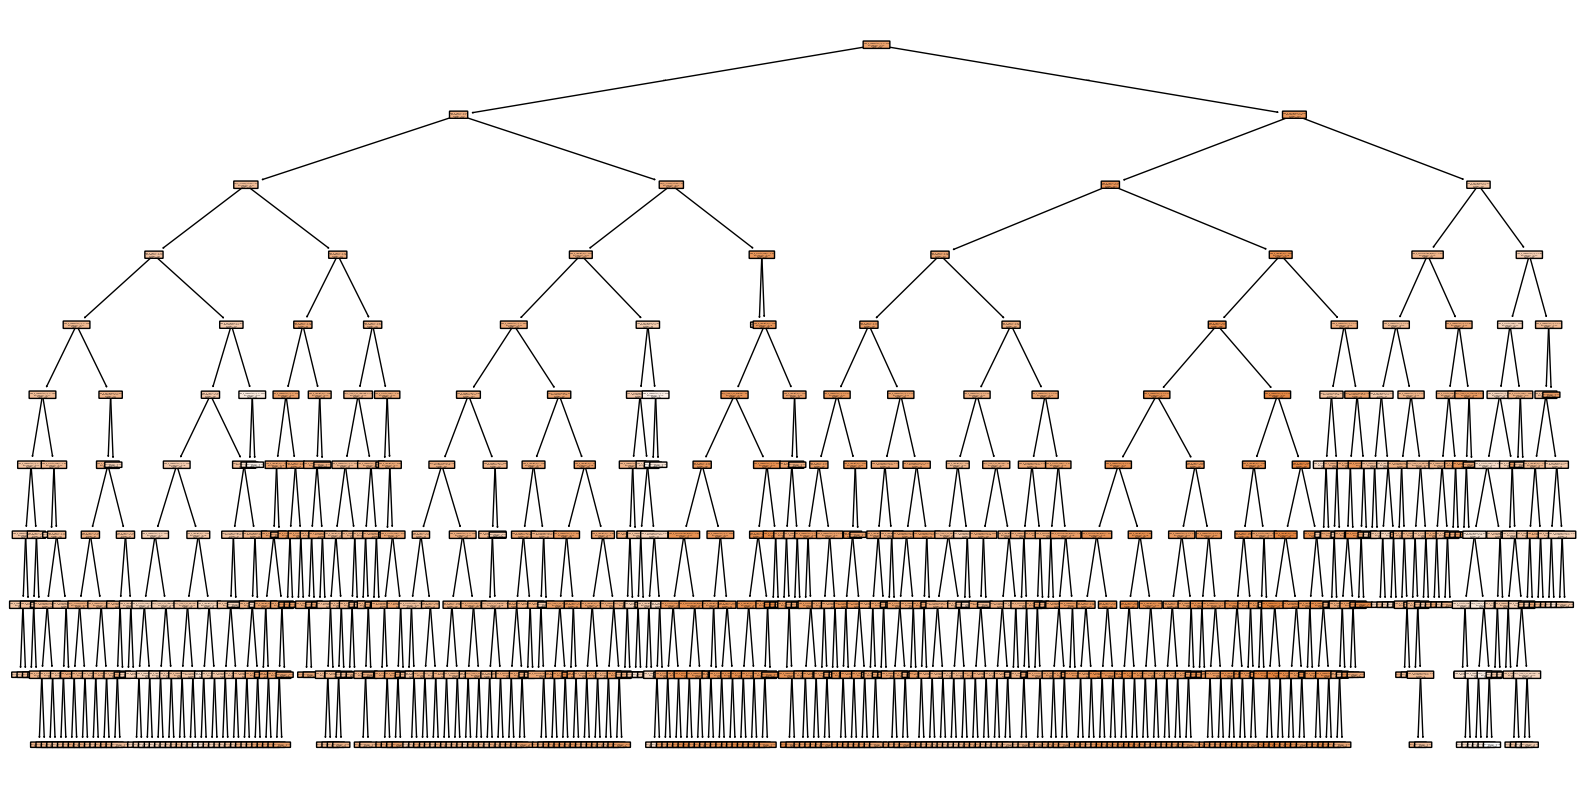

In [73]:
# ploting the decision tree 
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt
feature_names = preprocessor.get_feature_names_out()
plt.figure(figsize=(20,10))
plot_tree(
    dt_vis,
    feature_names=feature_names,
    filled=True,
    rounded=True
)
plt.show()

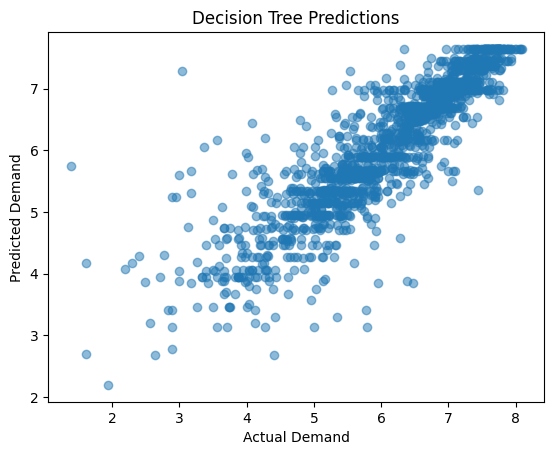

In [74]:
# visualizing predicted vs actual 

plt.scatter(y_test,y_pred_dt_grid, alpha=0.5)
plt.xlabel("Actual Demand")
plt.ylabel("Predicted Demand")
plt.title("Decision Tree Predictions")
plt.show()

In [75]:
# checking overfitting 
print("Train R2:", r2_score(y_train, dtgrid.predict(X_train_processed)))
print("Test R2:", r2_score(y_test, dtgrid.predict(X_test_processed)))
# so there is very healthy relationship and the model is well regulated

Train R2: 0.8996921835747793
Test R2: 0.7849944449876718


In [76]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint,uniform

param_dist = {
    'n_estimators': randint(200, 600),
    'max_depth': randint(8, 25),
    'min_samples_split': randint(10, 40),
    'min_samples_leaf': randint(5, 20),
    'max_features': ['sqrt', 'log2']
}

In [77]:
# random forest regressor
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

random_search = RandomizedSearchCV(
    rf,
    param_distributions=param_dist,
    n_iter=40,        
    cv=3,
    scoring='r2',
    n_jobs=-1,
    random_state=42
)

random_search.fit(X_train_processed, y_train)

best_rf = random_search.best_estimator_
print("Best parameters:", random_search.best_params_)

Best parameters: {'max_depth': 14, 'max_features': 'log2', 'min_samples_leaf': 5, 'min_samples_split': 10, 'n_estimators': 576}


In [78]:
rf_best = RandomForestRegressor(
    max_depth= 14,
    max_features= 'log2',
    min_samples_leaf= 5,
    min_samples_split= 10,
    n_estimators= 576,
    random_state = 42,
    n_jobs =-1,
    )

rf_best.fit(X_train_processed,y_train)
y_pred_rf_best = rf_best.predict(X_test_processed)
print("MSE:", mean_squared_error(y_test, y_pred_rf_best))
print("R2",r2_score(y_test,y_pred_rf_best))

MSE: 0.20679144386122042
R2 0.8386229049922778


In [79]:
# check overfitting 
print("Train R2:", r2_score(y_train, best_rf.predict(X_train_processed)))
print("Test R2:", r2_score(y_test, best_rf.predict(X_test_processed)))

Train R2: 0.8918158281818002
Test R2: 0.8386229049922778


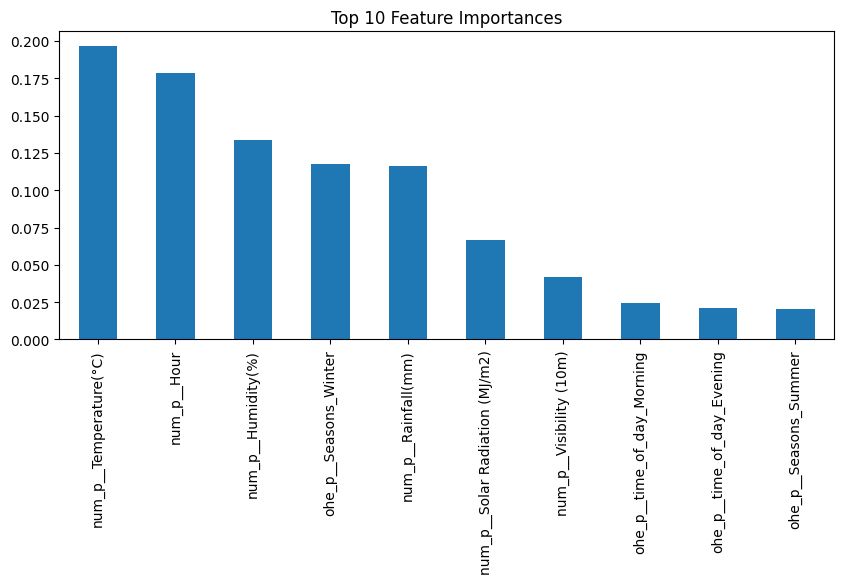

In [80]:
# printing the top 10 features 
importances = pd.Series(
    best_rf.feature_importances_,
    index=feature_names   # from preprocessor.get_feature_names_out()
).sort_values(ascending=False)

importances.head(10).plot(kind='bar', figsize=(10,4),
                          title="Top 10 Feature Importances")
plt.show()

In [81]:
# XGBoost Regressor 
from xgboost import XGBRegressor
xg = XGBRegressor(random_state=42,n_jobs=-1,eval_metric='rmse',early_stopping_rounds=50)


xg.fit(
    X_train_processed,
    y_train,
    eval_set=[(X_test_processed, y_test)],
    verbose=True
)

[0]	validation_0-rmse:0.88210
[1]	validation_0-rmse:0.71265
[2]	validation_0-rmse:0.61340
[3]	validation_0-rmse:0.54703
[4]	validation_0-rmse:0.51248
[5]	validation_0-rmse:0.49270
[6]	validation_0-rmse:0.47412
[7]	validation_0-rmse:0.46471
[8]	validation_0-rmse:0.46062
[9]	validation_0-rmse:0.45213
[10]	validation_0-rmse:0.44830
[11]	validation_0-rmse:0.44538
[12]	validation_0-rmse:0.44324
[13]	validation_0-rmse:0.44147
[14]	validation_0-rmse:0.43879
[15]	validation_0-rmse:0.43825
[16]	validation_0-rmse:0.43830
[17]	validation_0-rmse:0.43815
[18]	validation_0-rmse:0.43716
[19]	validation_0-rmse:0.43601
[20]	validation_0-rmse:0.43597
[21]	validation_0-rmse:0.43615
[22]	validation_0-rmse:0.43580
[23]	validation_0-rmse:0.43577
[24]	validation_0-rmse:0.43509
[25]	validation_0-rmse:0.43556
[26]	validation_0-rmse:0.43378
[27]	validation_0-rmse:0.43286
[28]	validation_0-rmse:0.43313
[29]	validation_0-rmse:0.43270
[30]	validation_0-rmse:0.43372
[31]	validation_0-rmse:0.43214
[32]	validation_0-

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=50,
             enable_categorical=False, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=-1, num_parallel_tree=None, ...)

In [82]:
y_pred_xg = xg.predict(X_test_processed)
print("MSE:", mean_squared_error(y_test, y_pred_xg))
print("R2",r2_score(y_test,y_pred_xg))

MSE: 0.18602222067944527
R2 0.8548309107011176


In [83]:
param_dist = {
    'n_estimators': randint(300, 900),
    'max_depth': randint(4, 9),
    'min_child_weight': randint(1, 8),
    'learning_rate': uniform(0.01, 0.09),
    'subsample': uniform(0.7, 0.3),
    'colsample_bytree': uniform(0.7, 0.3),
    'gamma': uniform(0, 0.5)
}

In [84]:
xgb = XGBRegressor(
    objective='reg:squarederror',
    eval_metric='rmse',
    random_state=42,
    n_jobs=-1
)


xg_random = RandomizedSearchCV(
    xgb,
    param_distributions=param_dist,
    n_iter=30,        
    cv=3,
    scoring='r2',
    n_jobs=-1,
    random_state=42
)
xg_random.fit(X_train_processed, y_train)

best_xgb = xg_random.best_estimator_
print("Best params:", xg_random.best_params_)

Best params: {'colsample_bytree': np.float64(0.916518856349462), 'gamma': np.float64(0.11799245987447787), 'learning_rate': np.float64(0.03304614904851916), 'max_depth': 6, 'min_child_weight': 1, 'n_estimators': 506, 'subsample': np.float64(0.8282623055075649)}


In [85]:
xg_random.fit(X_train_processed,y_train)
y_pred_xg_random = xg_random.predict(X_test_processed)
print("MSE:", mean_squared_error(y_test, y_pred_xg_random))
print("R2",r2_score(y_test,y_pred_xg_random))

MSE: 0.1726846432680605
R2 0.8652393659877609


In [86]:
# doing on log transformations 
xg_random.fit(X_train_processed,np.log1p(y_train))
y_pred_xg_random = xg_random.predict(X_test_processed)
print("MSE:", mean_squared_error(np.log1p(y_test), y_pred_xg_random))
print("R2",r2_score(np.log1p(y_test),y_pred_xg_random))

MSE: 0.005565247241809592
R2 0.8223090482908807


In [87]:
! pip install tensorflow


In [88]:
# ann implementation
import tensorflow as tf 
from tensorflow.keras.layers import Dense
from tensorflow.keras.models import Sequential
from tensorflow.keras.callbacks import EarlyStopping,TensorBoard
import datetime
model = Sequential()

2026-01-04 19:19:27.302599: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1767554367.829929      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1767554367.957919      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1767554369.151221      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1767554369.151272      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1767554369.151278      23 computation_placer.cc:177] computation placer alr

In [89]:
model.add(Dense(32, activation='relu', input_shape=(X_train_processed.shape[1],))) ## HL-1
model.add(Dense(16, activation='relu')) ## HL-2
model.add(Dense(1, activation='linear')) ## output layer

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1767554387.107413      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13542 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1767554387.108150      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [90]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           672 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,217 (4.75 KB)

 Trainable params: 1,217 (4.75 KB)

 Non-trainable params: 0 (0.00 B)

In [91]:
# compiling the model 
model.compile(optimizer="adam",loss="mse",metrics=['mae'])

In [92]:
## Set up the Tensorboard
log_dir = 'logs/fit/' + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorflow_callback = TensorBoard(log_dir=log_dir,histogram_freq=1)

In [93]:
## Set up Early Stopping
early_stopping_callback = EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True)

In [94]:
### Train the model
history = model.fit(X_train_processed,y_train,validation_data=(X_test_processed,y_test),epochs=100,callbacks=[early_stopping_callback,tensorflow_callback])

Epoch 1/100


I0000 00:00:1767554390.866663    1827 service.cc:152] XLA service 0x7be840006bc0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1767554390.866697    1827 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1767554390.866704    1827 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1767554391.188399    1827 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1767554392.217106    1827 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


212/212 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 27.3693 - mae: 4.7943 - val_loss: 0.8124 - val_mae: 0.6995
Epoch 2/100
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.7085 - mae: 0.6554 - val_loss: 0.5864 - val_mae: 0.5869
Epoch 3/100
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.5339 - mae: 0.5514 - val_loss: 0.4980 - val_mae: 0.5327
Epoch 4/100
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4719 - mae: 0.5037 - val_loss: 0.4487 - val_mae: 0.4955
Epoch 5/100
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4107 - mae: 0.4715 - val_loss: 0.4207 - val_mae: 0.4757
Epoch 6/100
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.4018 - mae: 0.4562 - val_loss: 0.4023 - val_mae: 0.4591
Epoch 7/100
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3728 - mae: 0.4408 - val_loss: 0.3919 - val_mae: 0.4504
Epoch 8/100
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.3676 - mae: 0.4343 - val_loss: 0.3936 - val_mae: 0.4531
Epoch 9/100
212/212 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - los